In [1]:
import torch
import torch.nn as nn
from torch import optim

from sinctdnn import SincTDNN

model = SincTDNN()
classes = 155
model.add_module('output', nn.Linear(512, classes))
model.add_module('softmax', nn.Softmax(dim=1))
# load_path = '/home/s226059/workspace/SpeakerEmbeddingLossComparison/models/AAM/train/VoxCeleb.SpeakerVerification.VoxCeleb2.train/weights/0560.pt'
load_path = '/home/s226059/workspace/self_sinctdnn/save_model/best20220903-073210/model_raw_47'
load_weights = torch.load(load_path)['model_state_dict']
model.load_state_dict(load_weights, strict=False)

# classes = 155
# model.add_module('output', nn.Linear(512, classes))
# model.add_module('softmax', nn.Softmax(dim=1))

# use_cuda = torch.cuda.is_available()
# device = torch.device("cuda" if use_cuda else "cpu")
# model.to(device)


/home/s226059/.conda/envs/pyan/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<All keys matched successfully>

In [2]:
load_saved_model = torch.load('/home/s226059/workspace/self_sinctdnn/save_model/best20220903-073210/model_raw_47')

In [36]:
optimizer_model = optim.RMSprop(model.parameters(), lr=0.0001, alpha=0.95, eps=1e-8)

In [39]:
optimizer_model.load_state_dict(load_saved_model['optimizer_state_dict'])
use_cuda = torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")
for state in optimizer_model.state.values():
    for k, v in state.items():
        if isinstance(v, torch.Tensor):
            state[k] = v.to(device)

In [2]:
losses = []
for i in range(94):
    losses.append(torch.load('/home/s226059/workspace/self_sinctdnn/save_model/best20220903-073210/model_raw_' + str(i))['loss'].item())

In [3]:
for i in losses:
    print(i)

4.980465412139893
4.609630584716797
4.915557861328125
5.1605401039123535
4.523334980010986
4.9199419021606445
4.805772304534912
4.284961700439453
4.471124172210693
4.925384998321533
4.269234657287598
4.684410572052002
4.267179012298584
4.042847633361816
4.244264602661133
4.136768817901611
4.972313404083252
4.158858299255371
4.474456310272217
3.9150032997131348
4.198159217834473
3.4596803188323975
3.577650785446167
3.8583285808563232
4.89240837097168
3.964364528656006
3.6933393478393555
3.3373889923095703
3.2443008422851562
4.151917457580566
2.996619701385498
3.5726141929626465
3.355130910873413
3.3204574584960938
3.3818154335021973
3.0888025760650635
2.676400899887085
3.290686845779419
3.7372143268585205
3.828639268875122
3.4646856784820557
2.598484516143799
3.5455381870269775
2.978853225708008
2.4286835193634033
3.1845321655273438
3.1738133430480957
2.0489819049835205
2.8246846199035645
2.405153274536133
2.719940185546875
3.2563846111297607
2.906013250350952
2.76666259765625
2.2604348

In [27]:
import numpy as np
min_loss = np.array(losses).min()
for i, ls in enumerate(losses):
    if ls == min_loss:
        print("min epoch is " + str(i))

min epoch is 47


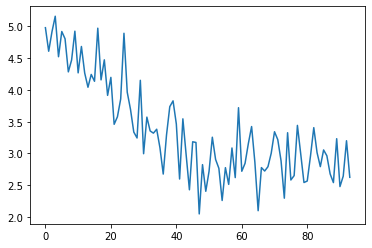

In [28]:
import matplotlib.pyplot as plt

plt.plot(losses)


In [28]:
import torch
import torch.nn as nn
from torch import optim

from sinctdnn import SincTDNN

model = SincTDNN()

In [36]:
model.state_dict()

OrderedDict([('sincnet_.waveform_normalize_.weight', tensor([13.5490])),
             ('sincnet_.waveform_normalize_.bias', tensor([2.9220])),
             ('sincnet_.conv1d_.0.low_hz_',
              tensor([[  30.7775],
                      [  52.7097],
                      [  76.0921],
                      [ 100.6895],
                      [ 125.5673],
                      [ 151.8131],
                      [ 178.4502],
                      [ 205.8250],
                      [ 234.3125],
                      [ 263.3082],
                      [ 293.4054],
                      [ 324.6665],
                      [ 356.8138],
                      [ 389.9370],
                      [ 424.0278],
                      [ 459.2355],
                      [ 495.6331],
                      [ 532.9825],
                      [ 571.6580],
                      [ 611.4849],
                      [ 652.4550],
                      [ 694.7411],
                      [ 738.4279],
        

In [10]:
from pyannote.audio import Model
pretrained = Model.from_pretrained("pyannote/embedding")
classes = 155
pretrained.add_module('output', nn.Linear(512, classes))
pretrained.add_module('softmax', nn.Softmax(dim=1))

In [20]:
from pyannote.database import get_protocol
vox = get_protocol('VoxCeleb.SpeakerVerification.VoxCeleb2')

In [27]:
from pyannote.audio.tasks import SpeakerEmbedding


In [2]:
import scipy
import scipy.io
import torch
import numpy as np


def ReadList(list_file):
    f = open(list_file, "r")
    lines = f.readlines()
    list_sig = []
    for x in lines:
        list_sig.append(x.rstrip())
    f.close()
    return list_sig


def create_batches_rnd(batch_size, data_folder, wav_lst, N_snt, wlen, lab_dict, age_to_lab, fact_amp):

    # Initialization of the minibatch (batch_size,[0=>x_t,1=>x_t+N,1=>random_samp])
    sig_batch = np.zeros([batch_size, wlen])
    lab_batch = np.zeros(batch_size)

    snt_id_arr = np.random.randint(N_snt, size=batch_size)

    rand_amp_arr = np.random.uniform(1.0-fact_amp, 1 + fact_amp, batch_size)

    for i in range(batch_size):

        # select a random sentence from the list  (joint distribution)
        [fs, signal] = scipy.io.wavfile.read(
            data_folder+wav_lst[snt_id_arr[i]])
        signal = signal.astype(float)/32768

        # accesing to a random chunk
        snt_len = signal.shape[0]
        # randint(0, snt_len-2*wlen-1)
        snt_beg = np.random.randint(snt_len-wlen-1)
        snt_end = snt_beg+wlen

        sig_batch[i, :] = signal[snt_beg:snt_end]*rand_amp_arr[i]

        # --------- #
        # a = snt_id_arr[i]
        # print(a)
        # a = wav_lst[a]
        # print(a)
        # a = lab_dict[a]
        # --------- #

        lab_batch[i] = age_to_lab[lab_dict[wav_lst[snt_id_arr[i]]]]

    inp = torch.from_numpy(sig_batch).float(
    ).cuda().contiguous().unsqueeze(dim=2)  # Current Frame
    lab = torch.from_numpy(lab_batch).float().cuda().contiguous()

    return inp, lab


In [10]:
length = 10
a = [1, 1, 1, 1, 1]
z = np.zeros(length - len(a))
b = np.concatenate((a, z))

In [11]:
b

array([1., 1., 1., 1., 1., 0., 0., 0., 0., 0.])

In [91]:
te_age_lst = ReadList('/home/s226059/workspace/self_sinctdnn/testing_age.txt')
te_age_dict = {}

for te_age in te_age_lst:
    a = te_age.split()
    print(a)
    te_age_dict.update({a[0]: a[1]})


['id00042/34f5sBShxSo/00001.wav', '70']
['id00042/34f5sBShxSo/00002.wav', '70']
['id00042/34f5sBShxSo/00003.wav', '70']
['id00042/34f5sBShxSo/00004.wav', '70']
['id00042/34f5sBShxSo/00005.wav', '70']
['id00042/34f5sBShxSo/00006.wav', '70']
['id00042/34f5sBShxSo/00007.wav', '70']
['id00042/34f5sBShxSo/00008.wav', '70']
['id00042/34f5sBShxSo/00009.wav', '70']
['id00042/34f5sBShxSo/00010.wav', '70']
['id00042/34f5sBShxSo/00011.wav', '70']
['id00042/34f5sBShxSo/00012.wav', '70']
['id00042/34f5sBShxSo/00013.wav', '70']
['id00042/34f5sBShxSo/00014.wav', '70']
['id00042/34f5sBShxSo/00015.wav', '70']
['id00042/34f5sBShxSo/00016.wav', '70']
['id00042/34f5sBShxSo/00017.wav', '70']
['id00042/34f5sBShxSo/00018.wav', '70']
['id00042/5KtWh0Q_mPM/00029.wav', '76']
['id00042/HFvwyu_Xk64/00034.wav', '70']
['id00042/HFvwyu_Xk64/00035.wav', '70']
['id00042/HFvwyu_Xk64/00036.wav', '70']
['id00042/HFvwyu_Xk64/00037.wav', '70']
['id00042/HFvwyu_Xk64/00038.wav', '70']
['id00042/HFvwyu_Xk64/00039.wav', '70']


In [63]:
age_to_lab = np.load(
    '/home/s226059/workspace/self_sinctdnn/age_to_lab.npy', allow_pickle=True).item()


In [92]:
te_age_dict

{'id00042/34f5sBShxSo/00001.wav': '70',
 'id00042/34f5sBShxSo/00002.wav': '70',
 'id00042/34f5sBShxSo/00003.wav': '70',
 'id00042/34f5sBShxSo/00004.wav': '70',
 'id00042/34f5sBShxSo/00005.wav': '70',
 'id00042/34f5sBShxSo/00006.wav': '70',
 'id00042/34f5sBShxSo/00007.wav': '70',
 'id00042/34f5sBShxSo/00008.wav': '70',
 'id00042/34f5sBShxSo/00009.wav': '70',
 'id00042/34f5sBShxSo/00010.wav': '70',
 'id00042/34f5sBShxSo/00011.wav': '70',
 'id00042/34f5sBShxSo/00012.wav': '70',
 'id00042/34f5sBShxSo/00013.wav': '70',
 'id00042/34f5sBShxSo/00014.wav': '70',
 'id00042/34f5sBShxSo/00015.wav': '70',
 'id00042/34f5sBShxSo/00016.wav': '70',
 'id00042/34f5sBShxSo/00017.wav': '70',
 'id00042/34f5sBShxSo/00018.wav': '70',
 'id00042/5KtWh0Q_mPM/00029.wav': '76',
 'id00042/HFvwyu_Xk64/00034.wav': '70',
 'id00042/HFvwyu_Xk64/00035.wav': '70',
 'id00042/HFvwyu_Xk64/00036.wav': '70',
 'id00042/HFvwyu_Xk64/00037.wav': '70',
 'id00042/HFvwyu_Xk64/00038.wav': '70',
 'id00042/HFvwyu_Xk64/00039.wav': '70',


In [93]:
np.save('testing_age_dict.npy', te_age_dict)


In [61]:
# 年齢をラベルに変換
lablist = ReadList('age_lab.txt')
lab_dict = {}
for lab in lablist:
    a = lab.split()
    print(a)
    lab_dict.update({a[0]: a[1]})


['7', '0']
['8', '1']
['9', '2']
['10', '3']
['11', '4']
['12', '5']
['13', '6']
['14', '7']
['15', '8']
['16', '9']
['17', '10']
['18', '11']
['19', '12']
['20', '13']
['21', '14']
['22', '15']
['23', '16']
['24', '17']
['25', '18']
['26', '19']
['27', '20']
['28', '21']
['29', '22']
['30', '23']
['31', '24']
['32', '25']
['33', '26']
['34', '27']
['35', '28']
['36', '29']
['37', '30']
['38', '31']
['39', '32']
['40', '33']
['41', '34']
['42', '35']
['43', '36']
['44', '37']
['45', '38']
['46', '39']
['47', '40']
['48', '41']
['49', '42']
['50', '43']
['51', '44']
['52', '45']
['53', '46']
['54', '47']
['55', '48']
['56', '49']
['57', '50']
['58', '51']
['59', '52']
['60', '53']
['61', '54']
['62', '55']
['63', '56']
['64', '57']
['65', '58']
['66', '59']
['67', '60']
['68', '61']
['69', '62']
['70', '63']
['71', '64']
['72', '65']
['73', '66']
['74', '67']
['75', '68']
['76', '69']
['77', '70']
['78', '71']
['79', '72']
['80', '73']
['81', '74']
['82', '75']
['83', '76']
['84', '77']

In [4]:
from torch.autograd import Variable

batch_size = 128
data_folder = '/home/s226059/workspace/data/age_training/wav/train/'
wav_lst_tr = ReadList('/home/s226059/workspace/self_sinctdnn/training_scp.txt')
snt_tr = len(wav_lst_tr)
N_snt = snt_tr
fs = 16000
cw_len = 200
cw_shift = 10
# wlen = int(fs*cw_len/1000.00)
wlen = int(fs*4.0)
lab_dict = np.load(
    '/home/s226059/workspace/self_sinctdnn/training_age_dict.npy', allow_pickle=True).item()
age_to_lab = np.load(
    '/home/s226059/workspace/self_sinctdnn/age_to_lab.npy', allow_pickle=True).item()
fact_amp = 0.2

[inp, lab] = create_batches_rnd(
    batch_size, data_folder, wav_lst_tr, snt_tr, wlen, lab_dict, age_to_lab, 0.2)


In [5]:
inp.shape

torch.Size([128, 16000, 1])

In [96]:
import os
import soundfile as sf
from torch.autograd import Variable

N_epochs = 5
N_eval_epoch = 1
N_batches = 128
lr = 0.001
cost = nn.NLLLoss()
optimizer_model = optim.RMSprop(
    model.parameters(), lr=lr, alpha=0.95, eps=1e-8)
batch_size = 32
data_folder = '/home/s226059/workspace/data/age_training/wav/train/'
wav_lst_tr = ReadList('/home/s226059/workspace/self_sinctdnn/training_scp.txt')
snt_tr = len(wav_lst_tr)
N_snt = snt_tr
fs = 16000
cw_len = 200
cw_shift = 10
wlen = int(fs*cw_len/1000.00)
lab_dict = np.load(
    '/home/s226059/workspace/self_sinctdnn/training_age_dict.npy', allow_pickle=True).item()
age_to_lab = np.load(
    '/home/s226059/workspace/self_sinctdnn/age_to_lab.npy', allow_pickle=True).item()
fact_amp = 0.2
wav_lst_te = '/home/s226059/workspace/self_sinctdnn/testing_scp.txt'
snt_te=len(wav_lst_te)
seed = 1234
output_folder = '/home/s226059/workspace/self_sinctdnn/save_model'

try:
    os.stat(output_folder)
except:
    os.mkdir(output_folder) 

# setting seed
torch.manual_seed(seed)
np.random.seed(seed)

# Converting context and shift in samples
wlen=int(fs*cw_len/1000.00)
wshift=int(fs*cw_shift/1000.00)

# Batch_dev
Batch_dev=128

In [95]:
for epoch in range(N_epochs):

    test_flag = 0
    model.train()

    loss_sum = 0
    err_sum = 0

    for i in range(N_batches):

        [inp, lab] = create_batches_rnd(
            batch_size, data_folder, wav_lst_tr, snt_tr, wlen, lab_dict, age_to_lab, 0.2)
        pout = (model(inp))

        pred = torch.max(pout, dim=1)[1]
        loss = cost(pout, lab.long())
        err = torch.mean((pred != lab.long()).float())

        optimizer_model.zero_grad()

        loss.backward()
        optimizer_model.step()

        loss_sum = loss_sum+loss.detach()
        err_sum = err_sum+err.detach()

    loss_tot = loss_sum/N_batches
    err_tot = err_sum/N_batches

    if epoch % N_eval_epoch == 0:

        model.eval()
        test_flag = 1
        loss_sum = 0
        err_sum = 0
        err_sum_snt = 0

        with torch.no_grad():
            for i in range(snt_te):

                # [fs,signal]=scipy.io.wavfile.read(data_folder+wav_lst_te[i])
                # signal=signal.astype(float)/32768

                [signal, fs] = sf.read(data_folder+wav_lst_te[i])

                signal = torch.from_numpy(signal).float().cuda().contiguous()
                lab_batch = lab_dict[wav_lst_te[i]]

                # split signals into chunks
                beg_samp = 0
                end_samp = wlen

                N_fr = int((signal.shape[0]-wlen)/(wshift))

                sig_arr = torch.zeros(
                    [Batch_dev, wlen]).float().cuda().contiguous()
                lab = Variable(
                    (torch.zeros(N_fr+1)+lab_batch).cuda().contiguous().long())
                pout = Variable(torch.zeros(
                    N_fr+1, 83).float().cuda().contiguous())
                count_fr = 0
                count_fr_tot = 0
                while end_samp < signal.shape[0]:
                    sig_arr[count_fr, :] = signal[beg_samp:end_samp]
                    beg_samp = beg_samp+wshift
                    end_samp = beg_samp+wlen
                    count_fr = count_fr+1
                    count_fr_tot = count_fr_tot+1
                    if count_fr == Batch_dev:
                        inp = Variable(sig_arr)
                        pout[count_fr_tot-Batch_dev:count_fr_tot,
                             :] = model(inp)
                        count_fr = 0
                        sig_arr = torch.zeros(
                            [Batch_dev, wlen]).float().cuda().contiguous()

                if count_fr > 0:
                    inp = Variable(sig_arr[0:count_fr])
                    pout[count_fr_tot-count_fr:count_fr_tot,
                         :] = model(inp)

                pred = torch.max(pout, dim=1)[1]
                loss = cost(pout, lab.long())
                err = torch.mean((pred != lab.long()).float())

                [val, best_class] = torch.max(torch.sum(pout, dim=0), 0)
                err_sum_snt = err_sum_snt+(best_class != lab[0]).float()

                loss_sum = loss_sum+loss.detach()
                err_sum = err_sum+err.detach()

            err_tot_dev_snt = err_sum_snt/snt_te
            loss_tot_dev = loss_sum/snt_te
            err_tot_dev = err_sum/snt_te

        print("epoch %i, loss_tr=%f err_tr=%f loss_te=%f err_te=%f err_te_snt=%f" % (
            epoch, loss_tot, err_tot, loss_tot_dev, err_tot_dev, err_tot_dev_snt))

        with open(output_folder+"/res.res", "a") as res_file:
            res_file.write("epoch %i, loss_tr=%f err_tr=%f loss_te=%f err_te=%f err_te_snt=%f\n" % (
                epoch, loss_tot, err_tot, loss_tot_dev, err_tot_dev, err_tot_dev_snt))

        checkpoint = {'model_par': model.state_dict()}
        torch.save(checkpoint, output_folder+'/model_raw.pkl')

    else:
        print("epoch %i, loss_tr=%f err_tr=%f" % (epoch, loss_tot, err_tot))


IndexError: Dimension out of range (expected to be in range of [-2, 1], but got 2)

In [1]:
import numpy as np
import random
audiosize = 195530
max_audio = 64000

startframe = np.array(np.int64(random.random()*(audiosize-max_audio)))

In [3]:
file = 'a/b/c/d/e/f'
file.split('/')[-4]

'c'

In [1]:
import sys, time, os, argparse, random
import importlib, itertools
import numpy
import glob
import datetime
import warnings

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.distributed as dist
import torch.multiprocessing as mp
from torch.cuda.amp import autocast, GradScaler

from sinctdnn import SincTDNN
from XvecDataloader import *

/home/s226059/.conda/envs/pyan/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
model = SincTDNN()
gpu = 1

os.environ['MASTER_ADDR']='localhost'
os.environ['MASTER_PORT']='8888'

dist.init_process_group(backend='nccl', world_size=1, rank=gpu)



In [3]:
torch.cuda.set_device(gpu)
model.cuda(gpu)

model = torch.nn.parallel.DistributedDataParallel(model, device_ids=[gpu], find_unused_parameters=True)

print('Loaded the model on GPU {:d}'.format(gpu))

In [4]:
n_gpus

3

In [4]:
a = 'x/y/z'
a.split('/')[0]

'x'